# RNN, LSTM and GRU on weather data, in Keras

The code for the video **"RNN, LSTM and GRU in Python: forecasting temperature from 14 weather measurements"**
(Deep Forecasting, Module 7, part 4.2). The theory is in the three videos before it: dense network vs RNN, the RNN,
the LSTM. The first notebook of this folder shows the same six steps on a small series; read that one first.

The task follows François Chollet, *Deep Learning with Python*: a weather station records 14 measurements every
10 minutes. Given the last 5 days, forecast the temperature 24 hours from now.

1. the data, split by time
2. prepare it, using the training part only
3. cut it into windows
4. a baseline to beat
5. build and train the models
6. score them in real units

Setup is not covered here: watch the setup video for the current year. A GPU is strongly recommended. Two of the
seven models are slow by design (the reason is part of the lesson); set `RUN_SLOW = False` to skip them.

In [1]:
import os, time, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers

print("keras", keras.__version__, "on", keras.backend.backend())
RUN_SLOW = True      # the two models with recurrent dropout: about 50 and 105 minutes on a recent GPU
EPOCHS = 10

I0000 00:00:1795198109.340477 2678824 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795198110.210642 2678824 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


keras 3.15.1 on tensorflow


## 1. The data, split by time

The Jena climate data: 14 measurements (pressure, temperature, humidity, wind ...) every 10 minutes from 2009 to
2016, recorded at the Max Planck Institute for Biogeochemistry. 420,451 rows.

In [2]:
path = "../data/jena_climate_2009_2016.csv"
if not os.path.exists(path):     # 13 MB, downloaded once
    os.makedirs("../data", exist_ok=True)
    urllib.request.urlretrieve("https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip", path + ".zip")
    zipfile.ZipFile(path + ".zip").extract("jena_climate_2009_2016.csv", "../data")

df = pd.read_csv(path)
print(df.shape)
df.head(3)

(420451, 15)


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6


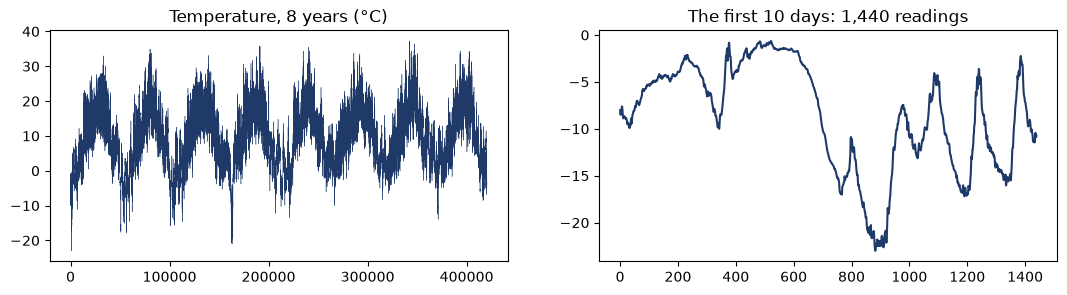

In [3]:
temperature = df["T (degC)"].to_numpy("float32")            # the target, in degrees Celsius
data = df.drop(columns="Date Time").to_numpy("float32")     # the 14 features (the temperature is one of them)

fig, ax = plt.subplots(1, 2, figsize=(13, 3))
ax[0].plot(temperature, lw=0.3, color="#1f3a68"); ax[0].set_title("Temperature, 8 years (°C)")
ax[1].plot(temperature[:1440], color="#1f3a68"); ax[1].set_title("The first 10 days: 1,440 readings")
plt.show()

Split by time: the first half for training, the next quarter for validation, the last quarter for the test.

In [4]:
n_train = int(0.5 * len(data))
n_val = int(0.25 * len(data))
print("train", n_train, "| validation", n_val, "| test", len(data) - n_train - n_val)

train 210225 | validation 105112 | test 105114


## 2. Prepare it

The 14 columns live on very different scales: pressure is around 990, humidity around 80, wind speed around 2.
Each column is rescaled to mean 0 and standard deviation 1, with the mean and standard deviation of the
**training** half only. The target stays in degrees, so every error below is in degrees.

In [5]:
mean = data[:n_train].mean(axis=0)
std = data[:n_train].std(axis=0)
data = (data - mean) / std
pd.DataFrame({"mean": mean, "std": std}, index=df.columns[1:]).round(2).T

,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
mean,988.75,8.83,282.910004,4.31,75.870003,13.15,9.19,3.95,5.81,9.3,1218.449951,2.15,3.56,176.440002
std,8.51,8.77,8.870000,7.08,16.629999,7.60,4.15,4.77,2.63,4.2,42.040001,1.53,2.32,85.849998


## 3. Cut it into windows

One sample: one reading per hour (every 6th row) for 5 days, so **120 time steps with 14 features**. Its target: the
temperature 24 hours after the window's last reading.

For a window that starts at row `s`, the readings are rows `s, s+6, ..., s+714`, and the target is row `s + 858`
(714 + 144: the last reading plus 24 hours of 10-minute rows).

In [6]:
RATE, LENGTH, AHEAD = 6, 120, 24                 # rows per hour, hours in, hours ahead
offsets = np.arange(LENGTH) * RATE               # 0, 6, ..., 714
delay = RATE * (LENGTH + AHEAD - 1)              # 858

def make_windows(start, end):
    """Windows that start in rows start ... end, each with the temperature 24 hours after its last reading."""
    starts = np.arange(start, min(end, len(data) - delay) - offsets[-1])
    X = data[starts[:, None] + offsets]          # (windows, 120, 14)
    y = temperature[starts + delay]
    return X, y

X_train, y_train = make_windows(0, n_train)
X_val, y_val = make_windows(n_train, n_train + n_val)
X_test, y_test = make_windows(n_train + n_val, len(data))
for name, X in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    print(f"{name:10s} {X.shape}   {X.nbytes / 1e9:.1f} GB")

train      (209511, 120, 14)   1.4 GB
validation (104398, 120, 14)   0.7 GB
test       (103542, 120, 14)   0.7 GB


## 4. A baseline to beat

"In 24 hours it will be as warm as it is now." The temperature is column 1; undo the scaling to get degrees.

In [7]:
def naive(X, y):
    now = X[:, -1, 1] * std[1] + mean[1]         # the last reading's temperature, back in degrees
    return float(np.mean(np.abs(now - y)))

results = {"temperature now (baseline)": {"test": naive(X_test, y_test), "validation": naive(X_val, y_val), "parameters": 0, "seconds per epoch": 0}}
print(f"validation {naive(X_val, y_val):.2f} degrees   test {naive(X_test, y_test):.2f} degrees")

validation 2.44 degrees   test 2.62 degrees


## 5. Build and train the models

One function trains any model the same way: mean squared error as the loss, the mean absolute error (in degrees) as
the number we read, 10 epochs, and the weights of the best validation epoch are the ones we test.

In [8]:
class Clock(keras.callbacks.Callback):
    """Remembers how long each epoch took."""
    def on_train_begin(self, logs=None): self.seconds = []
    def on_epoch_begin(self, epoch, logs=None): self.start = time.time()
    def on_epoch_end(self, epoch, logs=None): self.seconds.append(time.time() - self.start)

def run(name, *hidden_layers, epochs=EPOCHS, seed=0):
    keras.utils.set_random_seed(seed)
    inputs = keras.Input(shape=(LENGTH, data.shape[-1]))
    x = inputs
    for layer in hidden_layers:
        x = layer(x)
    model = keras.Model(inputs, layers.Dense(1)(x))
    model.compile(optimizer="rmsprop", loss="mse", metrics=["mae"])
    model.summary()
    clock = Clock()
    best = keras.callbacks.EarlyStopping(monitor="val_mae", patience=epochs, restore_best_weights=True)
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs, batch_size=256,
                        callbacks=[clock, best], verbose=2)
    test = model.evaluate(X_test, y_test, batch_size=1024, verbose=0)[1]
    results[name] = {"test": test, "validation": min(history.history["val_mae"]), "parameters": model.count_params(),
                     "seconds per epoch": float(np.mean(clock.seconds))}
    plt.figure(figsize=(7, 2.6))
    plt.plot(history.history["mae"], "o-", label="training", color="#1f3a68")
    plt.plot(history.history["val_mae"], "o-", label="validation", color="#e07b39")
    plt.axhline(results["temperature now (baseline)"]["validation"], color="grey", ls=":", label="baseline (validation)")
    plt.title(f"{name}: test error {test:.2f} degrees"); plt.xlabel("epoch"); plt.ylabel("degrees"); plt.legend(); plt.show()
    return model

### A dense network

`Flatten` unrolls a window into one long row: 120 x 14 = 1,680 numbers. Every one of them gets its own weight in
every unit: 1,680 x 16 + 16 = **26,896** parameters in the first layer.

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1680)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │        26,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,913 (105.13 KB)

 Trainable params: 26,913 (105.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 6s - 7ms/step - loss: 12.6639 - mae: 2.7415 - val_loss: 10.5254 - val_mae: 2.5696
Epoch 2/10
819/819 - 2s - 3ms/step - loss: 8.7806 - mae: 2.3307 - val_loss: 10.6795 - val_mae: 2.5793
Epoch 3/10
819/819 - 2s - 3ms/step - loss: 8.0869 - mae: 2.2381 - val_loss: 11.7259 - val_mae: 2.7077
Epoch 4/10
819/819 - 2s - 3ms/step - loss: 7.6379 - mae: 2.1754 - val_loss: 11.0742 - val_mae: 2.6313
Epoch 5/10
819/819 - 2s - 3ms/step - loss: 7.3067 - mae: 2.1272 - val_loss: 11.8669 - val_mae: 2.7351
Epoch 6/10
819/819 - 2s - 3ms/step - loss: 7.0804 - mae: 2.0944 - val_loss: 11.5810 - val_mae: 2.6975
Epoch 7/10
819/819 - 2s - 3ms/step - loss: 6.8917 - mae: 2.0664 - val_loss: 11.4492 - val_mae: 2.6811
Epoch 8/10
819/819 - 2s - 3ms/step - loss: 6.7548 - mae: 2.0458 - val_loss: 11.2719 - val_mae: 2.6567
Epoch 9/10
819/819 - 2s - 3ms/step - loss: 6.6305 - mae: 2.0281 - val_loss: 11.4518 - val_mae: 2.6773
Epoch 10/10
819/819 - 2s - 2ms/step - loss: 6.5344 - mae: 2.0125 - val_loss: 11.1

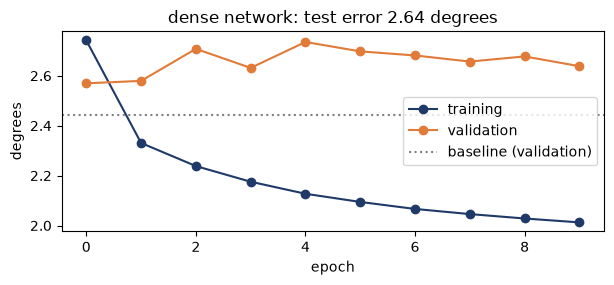

In [9]:
run("dense network", layers.Flatten(), layers.Dense(16, activation="relu"));

### A 1D convolution

A convolution slides a small window along the time axis and looks for the same pattern everywhere: 8 filters, each
24 hours wide over the 14 features (24 x 14 x 8 + 8 = 2,696 parameters). Pooling keeps the strongest response and
halves the length. It treats every position alike, which suits images better than a forecast, where the most recent
hours matter most.

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 97, 8)          │         2,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 48, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 37, 8)          │           776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 18, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 13, 8)          │           392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 8)              │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,873 (15.13 KB)

 Trainable params: 3,873 (15.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 9s - 11ms/step - loss: 21.5457 - mae: 3.6293 - val_loss: 16.0094 - val_mae: 3.1960
Epoch 2/10
819/819 - 3s - 3ms/step - loss: 14.6471 - mae: 3.0259 - val_loss: 15.4557 - val_mae: 3.1320
Epoch 3/10
819/819 - 3s - 3ms/step - loss: 13.4135 - mae: 2.8898 - val_loss: 14.7330 - val_mae: 3.0455
Epoch 4/10
819/819 - 3s - 3ms/step - loss: 12.6710 - mae: 2.8086 - val_loss: 14.6379 - val_mae: 3.0329
Epoch 5/10
819/819 - 3s - 4ms/step - loss: 12.1193 - mae: 2.7472 - val_loss: 14.1644 - val_mae: 2.9711
Epoch 6/10
819/819 - 4s - 5ms/step - loss: 11.7065 - mae: 2.7009 - val_loss: 13.9408 - val_mae: 2.9403
Epoch 7/10
819/819 - 3s - 4ms/step - loss: 11.3705 - mae: 2.6627 - val_loss: 14.0420 - val_mae: 2.9512
Epoch 8/10
819/819 - 3s - 4ms/step - loss: 11.0662 - mae: 2.6290 - val_loss: 13.9714 - val_mae: 2.9405
Epoch 9/10
819/819 - 3s - 3ms/step - loss: 10.7834 - mae: 2.5966 - val_loss: 13.8111 - val_mae: 2.9180
Epoch 10/10
819/819 - 3s - 3ms/step - loss: 10.5128 - mae: 2.5651 - val_

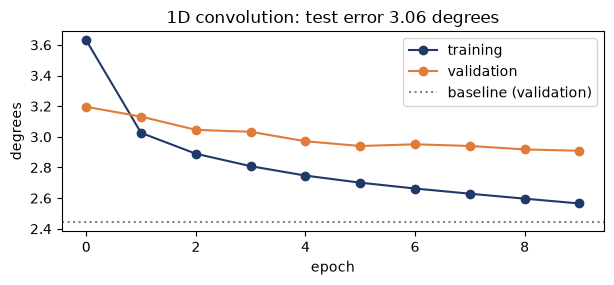

In [10]:
run("1D convolution",
    layers.Conv1D(8, 24, activation="relu"), layers.MaxPooling1D(2),
    layers.Conv1D(8, 12, activation="relu"), layers.MaxPooling1D(2),
    layers.Conv1D(8, 6, activation="relu"), layers.GlobalAveragePooling1D());

### The simple RNN

14 x 16 weights on the input, 16 x 16 on the previous state, 16 biases: **496** parameters, shared by all 120 steps.

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 28s - 35ms/step - loss: 52.6991 - mae: 5.3540 - val_loss: 15.3050 - val_mae: 2.8903
Epoch 2/10
819/819 - 25s - 31ms/step - loss: 11.8155 - mae: 2.6547 - val_loss: 9.4296 - val_mae: 2.3819
Epoch 3/10
819/819 - 26s - 31ms/step - loss: 10.4427 - mae: 2.5179 - val_loss: 9.1725 - val_mae: 2.3579
Epoch 4/10
819/819 - 26s - 32ms/step - loss: 10.2196 - mae: 2.4911 - val_loss: 9.1147 - val_mae: 2.3529
Epoch 5/10
819/819 - 26s - 32ms/step - loss: 10.0876 - mae: 2.4743 - val_loss: 9.0923 - val_mae: 2.3506
Epoch 6/10
819/819 - 26s - 32ms/step - loss: 9.9809 - mae: 2.4609 - val_loss: 9.0869 - val_mae: 2.3487
Epoch 7/10
819/819 - 26s - 32ms/step - loss: 9.9010 - mae: 2.4506 - val_loss: 9.0521 - val_mae: 2.3427
Epoch 8/10
819/819 - 26s - 32ms/step - loss: 9.8399 - mae: 2.4433 - val_loss: 9.0493 - val_mae: 2.3441
Epoch 9/10
819/819 - 26s - 32ms/step - loss: 9.8006 - mae: 2.4386 - val_loss: 9.0572 - val_mae: 2.3465
Epoch 10/10
819/819 - 26s - 32ms/step - loss: 9.7568 - mae: 2.4335 

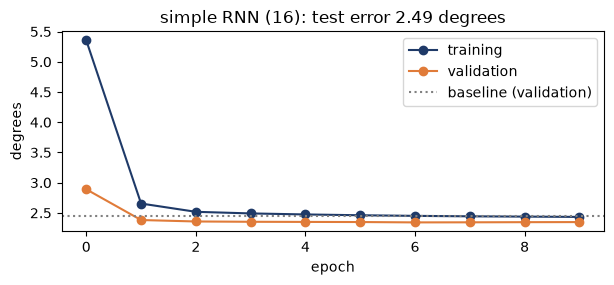

In [11]:
run("simple RNN (16)", layers.SimpleRNN(16));

### The LSTM

Three gates and a candidate, each with its own copy of those weights: 4 x 496 = **1,984**.

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 16)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,001 (7.82 KB)

 Trainable params: 2,001 (7.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 15s - 18ms/step - loss: 48.5653 - mae: 5.0971 - val_loss: 14.2206 - val_mae: 2.8448
Epoch 2/10
819/819 - 14s - 17ms/step - loss: 11.3058 - mae: 2.6109 - val_loss: 10.0199 - val_mae: 2.4636
Epoch 3/10
819/819 - 14s - 17ms/step - loss: 9.9181 - mae: 2.4564 - val_loss: 9.7054 - val_mae: 2.4273
Epoch 4/10
819/819 - 13s - 16ms/step - loss: 9.5491 - mae: 2.4094 - val_loss: 9.8003 - val_mae: 2.4400
Epoch 5/10
819/819 - 13s - 16ms/step - loss: 9.2800 - mae: 2.3755 - val_loss: 9.5773 - val_mae: 2.4060
Epoch 6/10
819/819 - 13s - 16ms/step - loss: 9.0626 - mae: 2.3474 - val_loss: 9.8297 - val_mae: 2.4476
Epoch 7/10
819/819 - 13s - 16ms/step - loss: 8.8736 - mae: 2.3210 - val_loss: 9.4379 - val_mae: 2.3961
Epoch 8/10
819/819 - 13s - 16ms/step - loss: 8.7085 - mae: 2.2975 - val_loss: 9.5941 - val_mae: 2.4166
Epoch 9/10
819/819 - 13s - 16ms/step - loss: 8.5799 - mae: 2.2792 - val_loss: 9.7094 - val_mae: 2.4208
Epoch 10/10
819/819 - 13s - 16ms/step - loss: 8.5420 - mae: 2.2745 - 

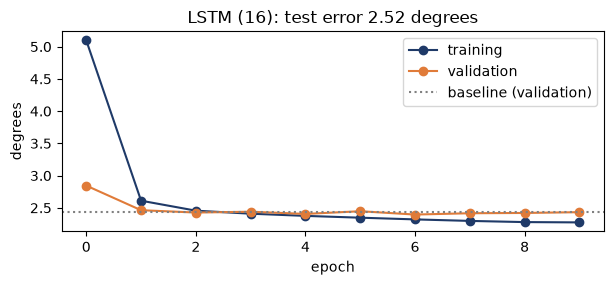

In [12]:
run("LSTM (16)", layers.LSTM(16));

### A bidirectional LSTM

Two LSTMs, one reading the window forward and one backward, their final states joined: 2 x 1,984 parameters. The
backward copy sees the most recent hours first and the oldest last.

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 32)             │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,001 (15.63 KB)

 Trainable params: 4,001 (15.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 23s - 28ms/step - loss: 30.6706 - mae: 3.9840 - val_loss: 10.8366 - val_mae: 2.5387
Epoch 2/10
819/819 - 22s - 27ms/step - loss: 9.7969 - mae: 2.4444 - val_loss: 9.9075 - val_mae: 2.4420
Epoch 3/10
819/819 - 22s - 27ms/step - loss: 8.8972 - mae: 2.3193 - val_loss: 9.6241 - val_mae: 2.4086
Epoch 4/10
819/819 - 22s - 27ms/step - loss: 8.4589 - mae: 2.2613 - val_loss: 10.1369 - val_mae: 2.4664
Epoch 5/10
819/819 - 23s - 28ms/step - loss: 7.9860 - mae: 2.1992 - val_loss: 9.8623 - val_mae: 2.4438
Epoch 6/10
819/819 - 23s - 28ms/step - loss: 7.6112 - mae: 2.1491 - val_loss: 10.2265 - val_mae: 2.4758
Epoch 7/10
819/819 - 23s - 28ms/step - loss: 7.3412 - mae: 2.1151 - val_loss: 10.4017 - val_mae: 2.5046
Epoch 8/10
819/819 - 23s - 28ms/step - loss: 7.0494 - mae: 2.0729 - val_loss: 10.1728 - val_mae: 2.4770
Epoch 9/10
819/819 - 22s - 27ms/step - loss: 6.8530 - mae: 2.0446 - val_loss: 10.2538 - val_mae: 2.4855
Epoch 10/10
819/819 - 22s - 27ms/step - loss: 6.6523 - mae: 2.0184

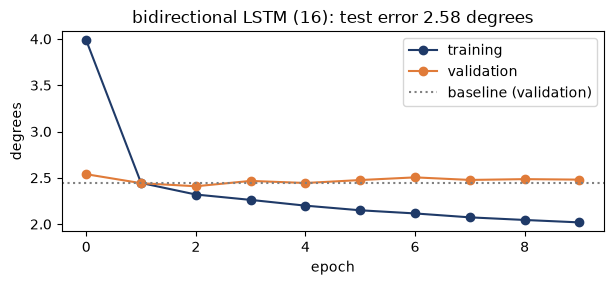

In [13]:
run("bidirectional LSTM (16)", layers.Bidirectional(layers.LSTM(16)));

### LSTM with recurrent dropout (slow)

A bigger LSTM (32 units) overfits, so it gets dropout. Inside the recurrent loop Keras uses `recurrent_dropout`:
one random mask per sequence, the same at every time step. The price: the layer can no longer use the fast GPU
routine for recurrent layers, and an epoch takes tens of times longer.

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │         6,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,049 (23.63 KB)

 Trainable params: 6,049 (23.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 384s - 468ms/step - loss: 30.4432 - mae: 4.0598 - val_loss: 9.5378 - val_mae: 2.3967
Epoch 2/10
819/819 - 382s - 466ms/step - loss: 15.0472 - mae: 3.0115 - val_loss: 9.3930 - val_mae: 2.3873
Epoch 3/10
819/819 - 379s - 462ms/step - loss: 14.2485 - mae: 2.9286 - val_loss: 9.0765 - val_mae: 2.3366
Epoch 4/10
819/819 - 379s - 463ms/step - loss: 13.6458 - mae: 2.8699 - val_loss: 8.7940 - val_mae: 2.3035
Epoch 5/10
819/819 - 380s - 464ms/step - loss: 13.3171 - mae: 2.8342 - val_loss: 8.7965 - val_mae: 2.2980
Epoch 6/10
819/819 - 381s - 465ms/step - loss: 13.0394 - mae: 2.8037 - val_loss: 8.7877 - val_mae: 2.2920
Epoch 7/10
819/819 - 383s - 467ms/step - loss: 12.7983 - mae: 2.7782 - val_loss: 8.6815 - val_mae: 2.2821
Epoch 8/10
819/819 - 391s - 478ms/step - loss: 12.5524 - mae: 2.7499 - val_loss: 8.7290 - val_mae: 2.2859
Epoch 9/10
819/819 - 379s - 463ms/step - loss: 12.4406 - mae: 2.7355 - val_loss: 8.6207 - val_mae: 2.2738
Epoch 10/10
819/819 - 371s - 454ms/step - loss

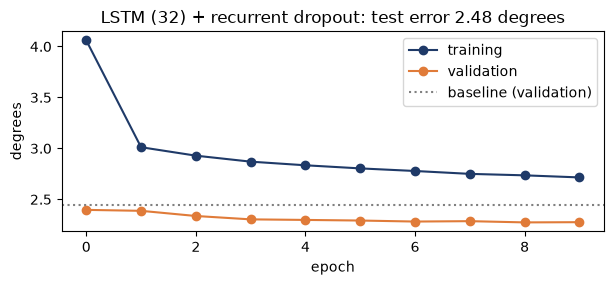

In [14]:
if RUN_SLOW:
    run("LSTM (32) + recurrent dropout", layers.LSTM(32, recurrent_dropout=0.25), layers.Dropout(0.5));

### Two stacked GRU layers with dropout (slower)

The GRU is a lighter cousin of the LSTM: two gates instead of three, and no separate cell state. The first layer
returns its state at every step (`return_sequences=True`) so that the second layer has a sequence to read.

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 120, 32)        │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         6,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,977 (42.88 KB)

 Trainable params: 10,977 (42.88 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 706s - 862ms/step - loss: 27.0281 - mae: 3.8225 - val_loss: 9.1651 - val_mae: 2.3373
Epoch 2/10
819/819 - 695s - 849ms/step - loss: 14.2352 - mae: 2.9249 - val_loss: 8.7322 - val_mae: 2.2884
Epoch 3/10
819/819 - 694s - 848ms/step - loss: 13.5117 - mae: 2.8472 - val_loss: 8.6573 - val_mae: 2.2859
Epoch 4/10
819/819 - 691s - 843ms/step - loss: 12.9889 - mae: 2.7931 - val_loss: 8.7729 - val_mae: 2.3014
Epoch 5/10
819/819 - 690s - 843ms/step - loss: 12.5356 - mae: 2.7458 - val_loss: 8.4778 - val_mae: 2.2564
Epoch 6/10
819/819 - 692s - 844ms/step - loss: 12.1439 - mae: 2.7045 - val_loss: 8.3814 - val_mae: 2.2464
Epoch 7/10
819/819 - 693s - 846ms/step - loss: 11.8421 - mae: 2.6698 - val_loss: 8.3814 - val_mae: 2.2461
Epoch 8/10
819/819 - 680s - 831ms/step - loss: 11.5730 - mae: 2.6401 - val_loss: 8.4433 - val_mae: 2.2558
Epoch 9/10
819/819 - 668s - 815ms/step - loss: 11.3342 - mae: 2.6123 - val_loss: 8.4158 - val_mae: 2.2536
Epoch 10/10
819/819 - 584s - 714ms/step - loss

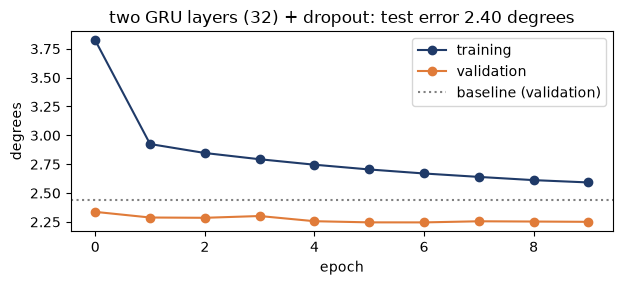

In [15]:
if RUN_SLOW:
    run("two GRU layers (32) + dropout",
        layers.GRU(32, recurrent_dropout=0.5, return_sequences=True),
        layers.GRU(32, recurrent_dropout=0.5), layers.Dropout(0.5));

## 6. Score them in real units

One table, one chart, everything in degrees on the test quarter. Each model was trained once here; in the video
the fast models are the middle of three runs. Your numbers will differ in the second decimal: the starting weights
are random, and a GPU does not add numbers in the same order twice.

In [16]:
table = pd.DataFrame(results).T
table["parameters"] = table["parameters"].astype(int)
table.round(2)

,test,validation,parameters,seconds per epoch
temperature now (baseline),2.62,2.44,0,0.00
dense network,2.64,2.57,26913,2.53
1D convolution,3.06,2.91,3873,3.59
simple RNN (16),2.49,2.34,513,26.17
LSTM (16),2.52,2.40,2001,13.49
bidirectional LSTM (16),2.58,2.41,4001,22.58
LSTM (32) + recurrent dropout,2.48,2.27,6049,380.87
two GRU layers (32) + dropout,2.40,2.25,10977,679.34


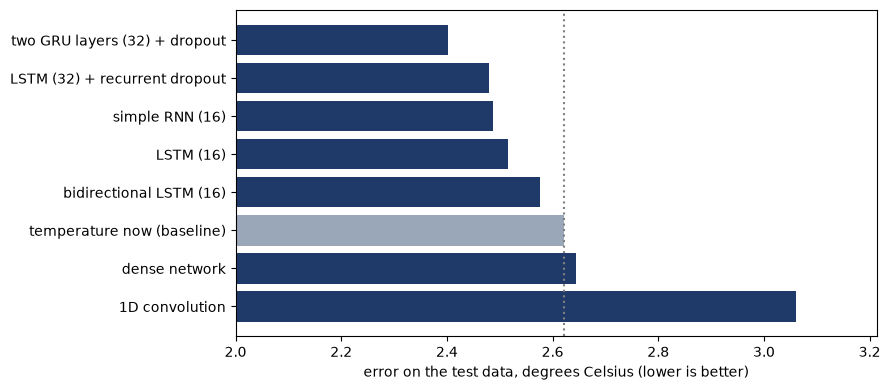

In [17]:
order = table.sort_values("test", ascending=False)
plt.figure(figsize=(9, 4))
plt.barh(order.index, order["test"], color=["#9aa7b8" if "baseline" in n else "#1f3a68" for n in order.index])
plt.axvline(table.loc["temperature now (baseline)", "test"], color="grey", ls=":")
plt.xlim(2, None); plt.xlabel("error on the test data, degrees Celsius (lower is better)"); plt.tight_layout(); plt.show()

## What this shows

- The baseline is hard to beat: a dense network with 27,000 weights does not manage it, and neither does the
  convolution.
- The recurrent models do, with a few hundred to a few thousand weights. They read the window in order and reuse the
  same weights at every hour.
- Reading the window backward as well does not help a forecast.
- Regularized, larger recurrent models gain a little more, and cost far more time.
- The gains are tenths of a degree. Weather 24 hours ahead from one station is a hard problem.

## Try it yourself, with a coding assistant

- "Forecast 12 hours ahead instead of 24." (Change `AHEAD`.)
- "Use only the temperature column as input, and compare."
- "Add a GRU with 16 units and no dropout to the table."
- "Rewrite this for PyTorch." or "Update this for the current version of Keras."

Then check what you get back: the shapes of the windows, that the split is by time, that the baseline is still in
the table, and that the test quarter is only used for the final score.